<a href="https://colab.research.google.com/github/sofiatrassi2025-lab/KidneySense-AI/blob/main/KidneySense_Module3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# 1. Charger ton dataset nettoyé
import os
chemin = "/clean_kfre.csv" if os.path.exists("/clean_kfre.csv") else "clean_kfre.csv"
df = pd.read_csv(chemin)
# 2. Vérifier dimensions et colonnes
print("Dimensions (lignes, colonnes) :", df.shape)
print("Colonnes exactes :", df.columns.tolist())

# 3. Vérifier les valeurs manquantes et doublons
print("\nValeurs manquantes par colonne :\n", df.isna().sum())
print("Doublons :", df.duplicated().sum())

# 4. Afficher un aperçu et les statistiques
print("\n5 premières lignes :")
display(df.head())

print("\nStatistiques descriptives :")
display(df.describe())

Dimensions (lignes, colonnes) : (35538, 16)
Colonnes exactes : ['id', 'age', 'gender', 'egfr', 'acr_mgmmol', 'acr_mg_g', 'log_acr', 'time_days', 'time_months', 'time_years', 'esrd', 'death', 'dm', 'hf', 'cvd', 'htn']

Valeurs manquantes par colonne :
 id             0
age            0
gender         0
egfr           0
acr_mgmmol     0
acr_mg_g       0
log_acr        0
time_days      0
time_months    0
time_years     0
esrd           0
death          0
dm             0
hf             0
cvd            0
htn            0
dtype: int64
Doublons : 0

5 premières lignes :


,id,age,gender,egfr,acr_mgmmol,acr_mg_g,log_acr,time_days,time_months,time_years,esrd,death,dm,hf,cvd,htn
0,1,80,0,57.0,4.2,37.13,3.64100,3226,105.99,8.8323,0,0,0,0,0,1
1,2,89,0,40.0,6.4,56.58,4.05318,1870,61.44,5.1198,0,0,0,0,0,0
2,3,92,0,32.0,0.9,7.96,2.19277,2344,77.01,6.4175,0,0,0,0,1,0
3,4,67,0,54.0,6.5,57.46,4.06834,699,22.97,1.9138,0,0,1,0,0,1
4,5,71,0,59.0,2.0,17.68,2.92745,1903,62.52,5.2101,0,0,0,0,1,0



Statistiques descriptives :


,id,age,gender,egfr,acr_mgmmol,acr_mg_g,log_acr,time_days,time_months,time_years,esrd,death,dm,hf,cvd,htn
count,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000,35538.000000
mean,17770.431088,75.936491,0.424954,48.241957,11.776676,104.105775,3.351830,1736.648827,57.056189,4.754685,0.015983,0.265828,0.314959,0.089791,0.320108,0.698773
std,10259.192408,10.604616,0.494343,9.834745,40.851127,361.123980,1.553994,929.582375,30.540568,2.545058,0.125411,0.441779,0.464506,0.285886,0.466524,0.458798
min,1.000000,18.000000,0.000000,10.000000,0.000000,0.000000,0.000000,1.000000,0.030000,0.002700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8886.250000,70.000000,0.000000,43.000000,1.200000,10.610000,2.451870,1010.000000,33.180000,2.765200,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,17770.500000,77.000000,0.000000,51.000000,3.200000,28.290000,3.377250,1720.000000,56.510000,4.709100,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,26654.750000,83.000000,1.000000,56.000000,8.000000,70.720000,4.272770,2413.000000,79.280000,6.606400,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,35539.000000,104.000000,1.000000,59.000000,1325.600000,11718.300000,9.368990,4423.000000,145.310000,12.109500,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Toutes les colonnes du dataset : ['id', 'age', 'gender', 'egfr', 'acr_mgmmol', 'acr_mg_g', 'log_acr', 'time_days', 'time_months', 'time_years', 'esrd', 'death', 'dm', 'hf', 'cvd', 'htn']
Nombre de patients avec acr_mg_g == 0 : 2239

Répartition des patients selon KDIGO :


,Nombre de patients,Pourcentage (%)
stade_kdigo,,
G3a,25448,71.61
G3b,7961,22.40
G4,1967,5.53
G5,162,0.46


/tmp/ipykernel_16115/783689496.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=effectifs.index, y=effectifs.values, palette=couleurs)


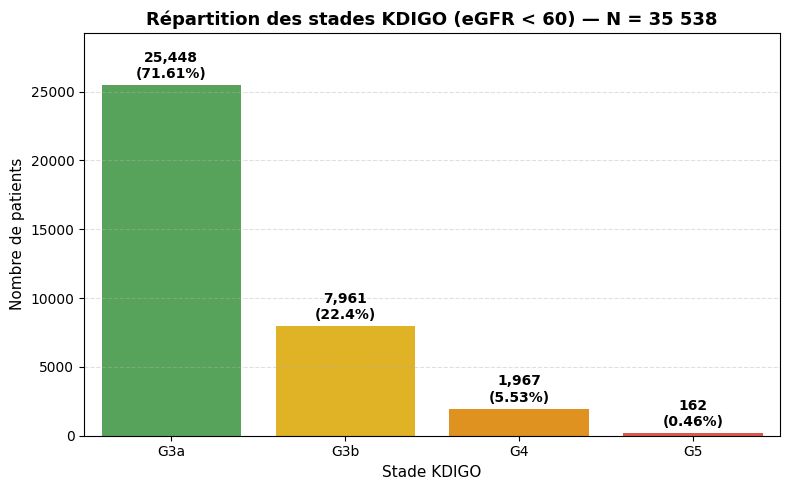

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 0. Afficher la liste complète des colonnes et vérifier les ACR == 0 (pour préparer la Phase 4)
print("Toutes les colonnes du dataset :", df.columns.tolist())
print("Nombre de patients avec acr_mg_g == 0 :", (df["acr_mg_g"] == 0).sum())

# 1. Fonction de stadification KDIGO (pour patients avec eGFR < 60)
def classer_kdigo(egfr):
    if egfr >= 45:
        return "G3a"
    elif egfr >= 30:
        return "G3b"
    elif egfr >= 15:
        return "G4"
    else:
        return "G5"

# 2. Appliquer la fonction à toute la colonne 'egfr'
df["stade_kdigo"] = df["egfr"].apply(classer_kdigo)

# 3. Construire le tableau récapitulatif (Effectif et Pourcentage)
ordre_stades = ["G3a", "G3b", "G4", "G5"]
effectifs = df["stade_kdigo"].value_counts().reindex(ordre_stades, fill_value=0)
pourcentages = (effectifs / len(df) * 100).round(2)

tableau_kdigo = pd.DataFrame({
    "Nombre de patients": effectifs,
    "Pourcentage (%)": pourcentages
})

print("\nRépartition des patients selon KDIGO :")
display(tableau_kdigo)

# 4. Visualisation graphique
plt.figure(figsize=(8, 5))
couleurs = ["#4CAF50", "#FFC107", "#FF9800", "#F44336"]
ax = sns.barplot(x=effectifs.index, y=effectifs.values, palette=couleurs)

plt.title("Répartition des stades KDIGO (eGFR < 60) — N = 35 538", fontsize=13, fontweight="bold")
plt.xlabel("Stade KDIGO", fontsize=11)
plt.ylabel("Nombre de patients", fontsize=11)

# Afficher les chiffres exacts au-dessus de chaque barre
for i, v in enumerate(effectifs.values):
    pct = pourcentages.iloc[i]
    ax.text(i, v + 300, f"{v:,}\n({pct}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.ylim(0, effectifs.max() * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [3]:
print("Colonnes :", df.columns.tolist())
display(df.iloc[:, :6].head(3))
print("Patients avec acr_mg_g == 0 :", (df["acr_mg_g"] == 0).sum())

Colonnes : ['id', 'age', 'gender', 'egfr', 'acr_mgmmol', 'acr_mg_g', 'log_acr', 'time_days', 'time_months', 'time_years', 'esrd', 'death', 'dm', 'hf', 'cvd', 'htn', 'stade_kdigo']


,id,age,gender,egfr,acr_mgmmol,acr_mg_g
0,1,80,0,57.0,4.2,37.13
1,2,89,0,40.0,6.4,56.58
2,3,92,0,32.0,0.9,7.96


Patients avec acr_mg_g == 0 : 2239


In [ ]:
print("Répartition de gender (proportions) :\n", df["gender"].value_counts(normalize=True).round(4))
print("Valeurs uniques de gender :", df["gender"].unique())
print("Dernières colonnes :", df.columns[15:].tolist())

Répartition de gender (proportions) :
 gender
0    0.575
1    0.425
Name: proportion, dtype: float64
Valeurs uniques de gender : [0 1]
Dernières colonnes : ['htn', 'stade_kdigo']


Aperçu des prédictions KFRE (%) :


,id,age,gender,egfr,acr_mg_g,stade_kdigo,kfre_2ans_pct,kfre_5ans_pct,esrd
0,1,80,0,57.0,37.13,G3a,0.058602,0.226730,0
1,2,89,0,40.0,56.58,G3b,0.385217,1.483407,0
2,3,92,0,32.0,7.96,G3b,0.362888,1.397872,0
3,4,67,0,54.0,57.46,G3a,0.132621,0.512557,0
4,5,71,0,59.0,17.68,G3a,0.040921,0.158361,0



Risque KFRE moyen/médian et taux réel d'ESRD par stade KDIGO :


,patients,kfre_2ans_moyen,kfre_2ans_median,kfre_5ans_moyen,kfre_5ans_median,esrd_reel_pct
stade_kdigo,,,,,,
G3a,25448,0.13,0.09,0.51,0.33,0.47
G3b,7961,0.86,0.49,3.19,1.87,2.20
G4,1967,6.21,3.19,19.15,11.78,10.63
G5,162,29.23,21.36,62.89,60.55,39.51



Validation sur les vrais cas ESRD :
 - Cas ESRD observés <= 2 ans : 176 | AUC-ROC KFRE 2 ans = 0.9323
 - Cas ESRD observés <= 5 ans : 429 | AUC-ROC KFRE 5 ans = 0.9237


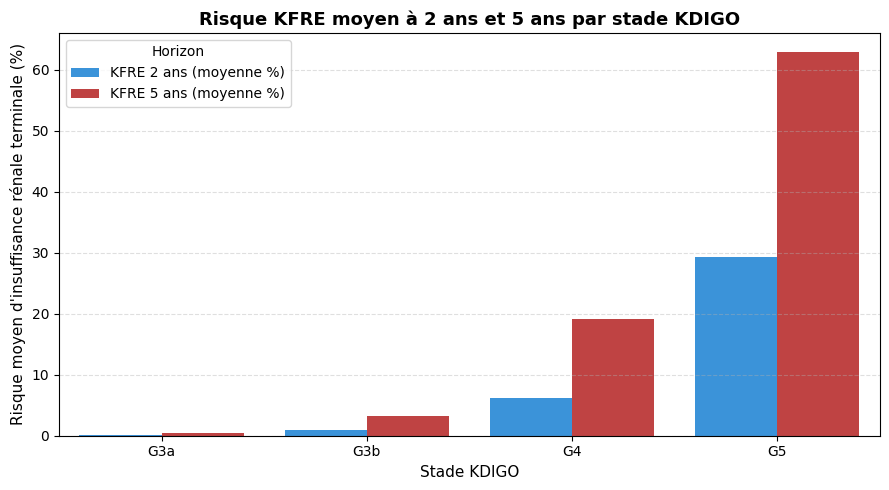

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# 1. Fonction validée KFRE à 4 variables (calibration non-nord-américaine, Tangri JAMA 2016)
def calculer_kfre(age, male, egfr, acr_mg_g):
    # Éviter log(0) pour les ACR indétectables
    acr_valide = np.clip(acr_mg_g, a_min=0.1, a_max=None)

    # Prédicteur linéaire L
    L = (
        -0.2201 * ((age / 10.0) - 7.036)
        + 0.2467 * (male - 0.5642)
        - 0.5567 * ((egfr / 5.0) - 7.222)
        + 0.4510 * (np.log(acr_valide) - 5.137)
    )

    # Survie de base (Non-North American)
    s0_2y = 0.9832
    s0_5y = 0.9365

    # Risque en pourcentage (%)
    risque_2ans = (1.0 - (s0_2y ** np.exp(L))) * 100.0
    risque_5ans = (1.0 - (s0_5y ** np.exp(L))) * 100.0

    return risque_2ans, risque_5ans

# 2. Appliquer KFRE à toute la cohorte
df["kfre_2ans_pct"], df["kfre_5ans_pct"] = calculer_kfre(
    df["age"], df["gender"], df["egfr"], df["acr_mg_g"]
)

# 3. Aperçu des résultats sur les 5 premiers patients
print("Aperçu des prédictions KFRE (%) :")
display(df[["id", "age", "gender", "egfr", "acr_mg_g", "stade_kdigo", "kfre_2ans_pct", "kfre_5ans_pct", "esrd"]].head())

# 4. Résumé par stade KDIGO
resume_stade = df.groupby("stade_kdigo").agg(
    patients=("id", "count"),
    kfre_2ans_moyen=("kfre_2ans_pct", "mean"),
    kfre_2ans_median=("kfre_2ans_pct", "median"),
    kfre_5ans_moyen=("kfre_5ans_pct", "mean"),
    kfre_5ans_median=("kfre_5ans_pct", "median"),
    esrd_reel_pct=("esrd", lambda x: x.mean() * 100)
).reindex(["G3a", "G3b", "G4", "G5"]).round(2)

print("\nRisque KFRE moyen/médian et taux réel d'ESRD par stade KDIGO :")
display(resume_stade)

# 5. Validation de l'équation KFRE sur les vrais événements observés (AUC-ROC)
esrd_2ans = ((df["esrd"] == 1) & (df["time_years"] <= 2)).astype(int)
esrd_5ans = ((df["esrd"] == 1) & (df["time_years"] <= 5)).astype(int)

auc_2ans = roc_auc_score(esrd_2ans, df["kfre_2ans_pct"])
auc_5ans = roc_auc_score(esrd_5ans, df["kfre_5ans_pct"])

print(f"\nValidation sur les vrais cas ESRD :")
print(f" - Cas ESRD observés <= 2 ans : {esrd_2ans.sum()} | AUC-ROC KFRE 2 ans = {auc_2ans:.4f}")
print(f" - Cas ESRD observés <= 5 ans : {esrd_5ans.sum()} | AUC-ROC KFRE 5 ans = {auc_5ans:.4f}")

# 6. Graphique : Risque KFRE moyen à 2 ans et 5 ans selon le stade KDIGO
fig, ax = plt.subplots(figsize=(9, 5))
resume_plot = resume_stade[["kfre_2ans_moyen", "kfre_5ans_moyen"]].reset_index().melt(
    id_vars="stade_kdigo", var_name="Horizon", value_name="Risque (%)"
)
resume_plot["Horizon"] = resume_plot["Horizon"].replace({
    "kfre_2ans_moyen": "KFRE 2 ans (moyenne %)",
    "kfre_5ans_moyen": "KFRE 5 ans (moyenne %)"
})

sns.barplot(data=resume_plot, x="stade_kdigo", y="Risque (%)", hue="Horizon", palette=["#2196F3", "#D32F2F"], ax=ax)
plt.title("Risque KFRE moyen à 2 ans et 5 ans par stade KDIGO", fontsize=13, fontweight="bold")
plt.xlabel("Stade KDIGO", fontsize=11)
plt.ylabel("Risque moyen d'insuffisance rénale terminale (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

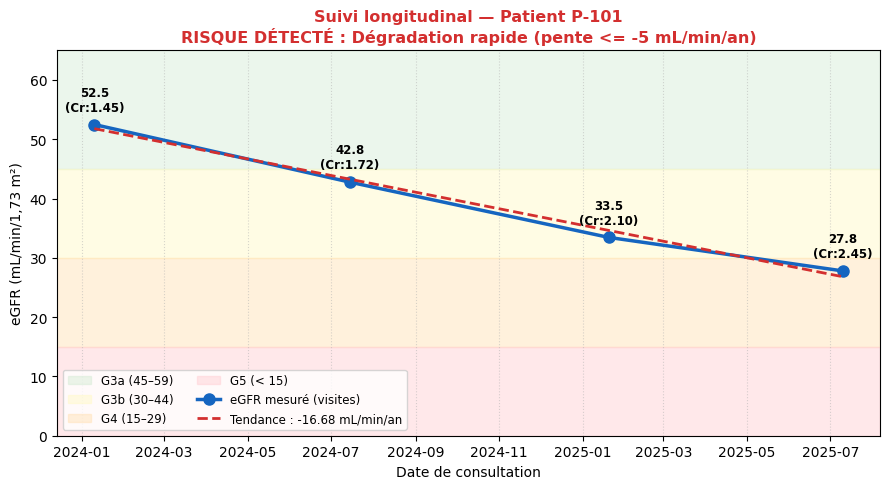

Résumé Patient P-101 | Début: 52.49 -> Actuel: 27.8 | Pente: -16.68 mL/min/1.73m²/an | Verdict: RISQUE DÉTECTÉ : Dégradation rapide (pente <= -5 mL/min/an)



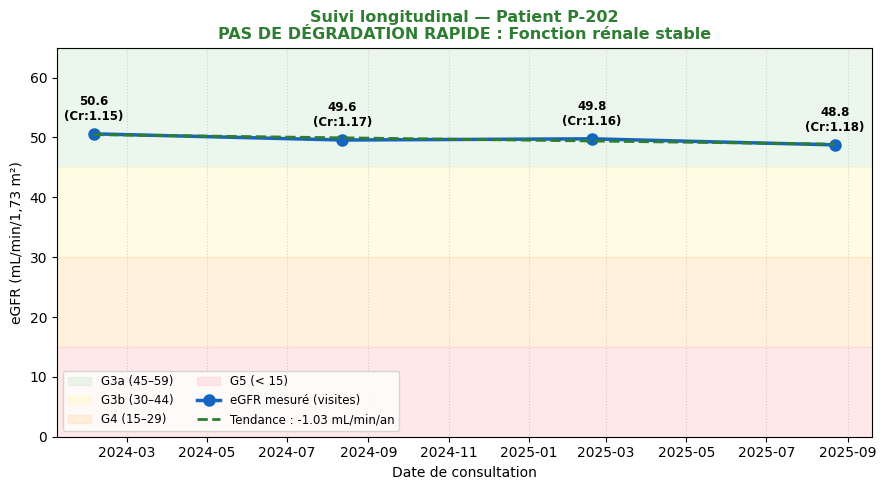

Résumé Patient P-202 | Début: 50.61 -> Actuel: 48.77 | Pente: -1.03 mL/min/1.73m²/an | Verdict: PAS DE DÉGRADATION RAPIDE : Fonction rénale stable



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Équation officielle CKD-EPI 2021 (créatinine en mg/dL, gender: 1=Homme, 0=Femme)
def calculer_egfr_ckdepi_2021(creatinine_mg_dl, age, gender):
    if gender == 0:  # Femme
        kappa, alpha, facteur_sexe = 0.7, -0.241, 1.012
    else:            # Homme
        kappa, alpha, facteur_sexe = 0.9, -0.302, 1.0

    ratio = creatinine_mg_dl / kappa
    egfr = 142 * (min(ratio, 1.0) ** alpha) * (max(ratio, 1.0) ** -1.200) * (0.9938 ** age) * facteur_sexe
    return round(egfr, 2)

# 2. Fonction d'analyse longitudinale et de génération du diagramme pour un patient
def analyser_suivi_patient(df_visites, patient_id):
    # Filtrer et trier les consultations du patient par date
    pat = df_visites[df_visites["patient_id"] == patient_id].copy()
    pat["visit_date"] = pd.to_datetime(pat["visit_date"])
    pat = pat.sort_values("visit_date").reset_index(drop=True)

    if len(pat) < 2:
        print(f"Patient {patient_id} : au moins 2 consultations sont nécessaires pour calculer la pente.")
        return

    # Calculer le temps écoulé en années depuis la 1ère consultation
    t_annees = (pat["visit_date"] - pat["visit_date"].iloc[0]).dt.days / 365.25

    if t_annees.iloc[-1] == 0:
        print("Les dates des consultations doivent être différentes.")
        return

    # Calculer la pente (eGFR slope en mL/min/1.73m²/an) et l'ordonnée à l'origine
    pente, intercept = np.polyfit(t_annees, pat["egfr"], 1)
    egfr_debut = pat["egfr"].iloc[0]
    egfr_actuel = pat["egfr"].iloc[-1]
    variation_pct = ((egfr_actuel - egfr_debut) / egfr_debut) * 100

    # Évaluation médicale du risque de progression rapide (critères KDIGO)
    if egfr_actuel < 15:
        statut = "ALERTE CRITIQUE : Stade G5 atteint (eGFR < 15) — Risque élevé"
        couleur_statut = "#B71C1C"
    elif pente <= -5.0:
        statut = "RISQUE DÉTECTÉ : Dégradation rapide (pente <= -5 mL/min/an)"
        couleur_statut = "#D32F2F"
    elif pente <= -3.0 or variation_pct <= -25.0:
        statut = "VIGILANCE : Déclin modéré — Surveillance rapprochée"
        couleur_statut = "#F57C00"
    else:
        statut = "PAS DE DÉGRADATION RAPIDE : Fonction rénale stable"
        couleur_statut = "#2E7D32"

    # Tracé du diagramme longitudinal
    fig, ax = plt.subplots(figsize=(9, 5))

    # Zones KDIGO en arrière-plan
    ax.axhspan(45, 65, color="#C8E6C9", alpha=0.35, label="G3a (45–59)")
    ax.axhspan(30, 45, color="#FFF9C4", alpha=0.45, label="G3b (30–44)")
    ax.axhspan(15, 30, color="#FFE0B2", alpha=0.45, label="G4 (15–29)")
    ax.axhspan(0, 15,  color="#FFCDD2", alpha=0.45, label="G5 (< 15)")

    # Courbe réelle des visites
    ax.plot(pat["visit_date"], pat["egfr"], marker="o", markersize=8, linewidth=2.5,
            color="#1565C0", label="eGFR mesuré (visites)")

    # Droite de tendance (pente eGFR)
    egfr_tendance = pente * t_annees + intercept
    ax.plot(pat["visit_date"], egfr_tendance, linestyle="--", linewidth=2,
            color=couleur_statut, label=f"Tendance : {pente:+.2f} mL/min/an")

    # Annoter chaque point avec sa valeur
    for _, row in pat.iterrows():
        ax.annotate(f"{row['egfr']:.1f}\n(Cr:{row['creatinine']:.2f})",
                    (row["visit_date"], row["egfr"]),
                    textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8.5, fontweight="bold")

    ax.set_ylim(0, max(65, pat["egfr"].max() + 8))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.set_title(f"Suivi longitudinal — Patient {patient_id}\n{statut}", fontsize=11.5, fontweight="bold", color=couleur_statut)
    ax.set_xlabel("Date de consultation")
    ax.set_ylabel("eGFR (mL/min/1,73 m²)")
    ax.legend(loc="lower left", fontsize=8.5, ncol=2)
    ax.grid(axis="x", linestyle=":", alpha=0.5)
    plt.tight_layout()
    plt.show()

    print(f"Résumé Patient {patient_id} | Début: {egfr_debut} -> Actuel: {egfr_actuel} | Pente: {pente:+.2f} mL/min/1.73m²/an | Verdict: {statut}\n")

# 3. Test sur 2 cas cliniques de démonstration (saisies simulées d'un médecin)
visites_demo = pd.DataFrame([
    # Cas A : Patient en dégradation rapide (perte rapide de fonction rénale)
    {"patient_id": "P-101", "visit_date": "2024-01-10", "age": 68, "gender": 1, "creatinine": 1.45},
    {"patient_id": "P-101", "visit_date": "2024-07-15", "age": 68, "gender": 1, "creatinine": 1.72},
    {"patient_id": "P-101", "visit_date": "2025-01-20", "age": 69, "gender": 1, "creatinine": 2.10},
    {"patient_id": "P-101", "visit_date": "2025-07-10", "age": 69, "gender": 1, "creatinine": 2.45},

    # Cas B : Patient stable (G3a stable dans le temps)
    {"patient_id": "P-202", "visit_date": "2024-02-05", "age": 72, "gender": 0, "creatinine": 1.15},
    {"patient_id": "P-202", "visit_date": "2024-08-12", "age": 72, "gender": 0, "creatinine": 1.17},
    {"patient_id": "P-202", "visit_date": "2025-02-18", "age": 73, "gender": 0, "creatinine": 1.16},
    {"patient_id": "P-202", "visit_date": "2025-08-22", "age": 73, "gender": 0, "creatinine": 1.18},
])

# Calcul automatique de l'eGFR à chaque visite
visites_demo["egfr"] = visites_demo.apply(
    lambda r: calculer_egfr_ckdepi_2021(r["creatinine"], r["age"], r["gender"]), axis=1
)

analyser_suivi_patient(visites_demo, "P-101")
analyser_suivi_patient(visites_demo, "P-202")

In [6]:
%%writefile module3_logic.py
import numpy as np
import pandas as pd


def calculer_egfr_ckdepi_2021(creatinine_mg_dl: float, age: float, gender: int) -> float:
    """
    Calcule l'eGFR (mL/min/1.73 m²) selon l'équation CKD-EPI 2021 (sans facteur ethnique).
    gender : 1 = Homme, 0 = Femme
    creatinine_mg_dl : créatinine sérique en mg/dL
    """
    if gender == 0:  # Femme
        kappa, alpha, facteur_sexe = 0.7, -0.241, 1.012
    else:            # Homme
        kappa, alpha, facteur_sexe = 0.9, -0.302, 1.0

    ratio = creatinine_mg_dl / kappa
    egfr = (
        142.0
        * (min(ratio, 1.0) ** alpha)
        * (max(ratio, 1.0) ** -1.200)
        * (0.9938 ** age)
        * facteur_sexe
    )
    return round(float(egfr), 2)


def classer_stade_kdigo(egfr: float) -> str:
    """
    Détermine le stade KDIGO. Le Module 3 cible exclusivement eGFR < 60.
    """
    if egfr >= 60:
        return "Hors Module 3 (eGFR >= 60)"
    elif egfr >= 45:
        return "G3a"
    elif egfr >= 30:
        return "G3b"
    elif egfr >= 15:
        return "G4"
    else:
        return "G5"


def calculer_kfre(age, male, egfr, acr_mg_g):
    """
    Équation validée Kidney Failure Risk Equation (KFRE) à 4 variables
    (Tangri et al., JAMA 2016 - Calibration non-nord-américaine).
    Retourne (risque_2ans_pct, risque_5ans_pct).
    """
    acr_valide = np.clip(acr_mg_g, a_min=0.1, a_max=None)

    L = (
        -0.2201 * ((age / 10.0) - 7.036)
        + 0.2467 * (male - 0.5642)
        - 0.5567 * ((egfr / 5.0) - 7.222)
        + 0.4510 * (np.log(acr_valide) - 5.137)
    )

    risque_2ans = (1.0 - (0.9832 ** np.exp(L))) * 100.0
    risque_5ans = (1.0 - (0.9365 ** np.exp(L))) * 100.0
    return risque_2ans, risque_5ans


def analyser_progression(df_visites_patient: pd.DataFrame) -> dict:
    """
    Analyse l'historique longitudinal d'un patient (minimum 2 visites à des dates différentes).
    Retourne un dictionnaire avec la pente eGFR (mL/min/1.73 m²/an) et le verdict d'alerte.
    """
    pat = df_visites_patient.copy()
    pat["visit_date"] = pd.to_datetime(pat["visit_date"])
    pat = pat.sort_values("visit_date").reset_index(drop=True)

    egfr_actuel = float(pat["egfr"].iloc[-1])
    stade_actuel = classer_stade_kdigo(egfr_actuel)

    if len(pat) < 2:
        return {
            "suffisant": False,
            "message": "Au moins 2 consultations sont nécessaires pour calculer la pente d'évolution.",
            "egfr_actuel": egfr_actuel,
            "stade_actuel": stade_actuel,
            "df_trie": pat,
        }

    t_annees = (pat["visit_date"] - pat["visit_date"].iloc[0]).dt.days / 365.25
    if t_annees.iloc[-1] <= 0:
        return {
            "suffisant": False,
            "message": "Les consultations doivent avoir des dates différentes.",
            "egfr_actuel": egfr_actuel,
            "stade_actuel": stade_actuel,
            "df_trie": pat,
        }

    pente, intercept = np.polyfit(t_annees, pat["egfr"], 1)
    egfr_debut = float(pat["egfr"].iloc[0])
    variation_pct = ((egfr_actuel - egfr_debut) / egfr_debut) * 100.0

    # Critères cliniques KDIGO
    if egfr_actuel < 15:
        niveau = "CRITIQUE"
        statut = "ALERTE CRITIQUE : Stade G5 atteint (eGFR < 15)"
        couleur = "#B71C1C"
    elif pente <= -5.0:
        niveau = "ELEVE"
        statut = "RISQUE DÉTECTÉ : Dégradation rapide (pente <= -5 mL/min/an)"
        couleur = "#D32F2F"
    elif pente <= -3.0 or variation_pct <= -25.0:
        niveau = "MODERE"
        statut = "VIGILANCE : Déclin modéré — Surveillance rapprochée"
        couleur = "#F57C00"
    else:
        niveau = "FAIBLE"
        statut = "PAS DE DÉGRADATION RAPIDE : Fonction rénale stable"
        couleur = "#2E7D32"

    return {
        "suffisant": True,
        "pente_annuelle": float(pente),
        "intercept": float(intercept),
        "t_annees": t_annees,
        "egfr_debut": egfr_debut,
        "egfr_actuel": egfr_actuel,
        "stade_actuel": stade_actuel,
        "variation_pct": float(variation_pct),
        "niveau": niveau,
        "statut": statut,
        "couleur": couleur,
        "df_trie": pat,
    }

Overwriting module3_logic.py


In [7]:
!pip install -q streamlit

In [8]:
%%writefile app_module3.py
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import streamlit as st

from module3_logic import (
    calculer_egfr_ckdepi_2021,
    classer_stade_kdigo,
    calculer_kfre,
    analyser_progression,
)

st.set_page_config(
    page_title="KidneySense AI — Module 3 (CKD Avancée)",
    layout="wide",
)

HISTORIQUE_FILE = "historique_consultations.csv"


@st.cache_data
def charger_cohorte():
    chemins = ["/clean_kfre.csv", "clean_kfre.csv", "/content/clean_kfre.csv"]
    for chemin in chemins:
        if os.path.exists(chemin):
            data = pd.read_csv(chemin)
            data["stade_kdigo"] = data["egfr"].apply(classer_stade_kdigo)
            data["kfre_2ans_pct"], data["kfre_5ans_pct"] = calculer_kfre(
                data["age"], data["gender"], data["egfr"], data["acr_mg_g"]
            )
            return data
    return None


def charger_historique():
    colonnes = ["patient_id", "visit_date", "age", "gender", "creatinine", "egfr", "acr_mg_g", "stade_kdigo", "kfre_2ans", "kfre_5ans"]
    if os.path.exists(HISTORIQUE_FILE):
        return pd.read_csv(HISTORIQUE_FILE)
    return pd.DataFrame(columns=colonnes)


def sauvegarder_historique(df_hist):
    df_hist.to_csv(HISTORIQUE_FILE, index=False)


st.title("KidneySense AI — Module 3 : CKD Avancée (eGFR < 60)")
st.caption("Stadification automatique KDIGO • Prédiction KFRE validée (2 ans & 5 ans) • Suivi longitudinal")

tab1, tab2, tab3 = st.tabs([
    "1. Consultation Médecin & Suivi Longitudinal",
    "2. Analyse Cohorte Clinique (N = 35 538)",
    "3. Méthodologie & Limites",
])

# ==============================================================================
# ONGLET 1 : INTERFACE MÉDECIN (ACTIONS 1, 2 ET 3)
# ==============================================================================
with tab1:
    col_form, col_res = st.columns([1, 1.6])

    df_hist = charger_historique()

    with col_form:
        st.subheader("Nouvelle consultation patient")

        if st.button("Charger 2 patients exemples (P-101 & P-202)"):
            exemples = pd.DataFrame([
                {"patient_id": "P-101", "visit_date": "2024-01-10", "age": 68, "gender": 1, "creatinine": 1.45, "acr_mg_g": 180.0},
                {"patient_id": "P-101", "visit_date": "2024-07-15", "age": 68, "gender": 1, "creatinine": 1.72, "acr_mg_g": 210.0},
                {"patient_id": "P-101", "visit_date": "2025-01-20", "age": 69, "gender": 1, "creatinine": 2.10, "acr_mg_g": 250.0},
                {"patient_id": "P-101", "visit_date": "2025-07-10", "age": 69, "gender": 1, "creatinine": 2.45, "acr_mg_g": 310.0},
                {"patient_id": "P-202", "visit_date": "2024-02-05", "age": 72, "gender": 0, "creatinine": 1.15, "acr_mg_g": 40.0},
                {"patient_id": "P-202", "visit_date": "2024-08-12", "age": 72, "gender": 0, "creatinine": 1.17, "acr_mg_g": 42.0},
                {"patient_id": "P-202", "visit_date": "2025-02-18", "age": 73, "gender": 0, "creatinine": 1.16, "acr_mg_g": 38.0},
                {"patient_id": "P-202", "visit_date": "2025-08-22", "age": 73, "gender": 0, "creatinine": 1.18, "acr_mg_g": 45.0},
            ])
            exemples["egfr"] = exemples.apply(
                lambda r: calculer_egfr_ckdepi_2021(r["creatinine"], r["age"], r["gender"]), axis=1
            )
            exemples["stade_kdigo"] = exemples["egfr"].apply(classer_stade_kdigo)
            exemples["kfre_2ans"], exemples["kfre_5ans"] = calculer_kfre(
                exemples["age"], exemples["gender"], exemples["egfr"], exemples["acr_mg_g"]
            )
            exemples["kfre_2ans"] = exemples["kfre_2ans"].round(2)
            exemples["kfre_5ans"] = exemples["kfre_5ans"].round(2)
            df_hist = pd.concat([df_hist, exemples], ignore_index=True).drop_duplicates(subset=["patient_id", "visit_date"])
            sauvegarder_historique(df_hist)
            st.success("Patients P-101 et P-202 chargés !")

        mode_saisie = st.radio(
            "Mode de saisie de la fonction rénale :",
            ["Calculer eGFR depuis la Créatinine (CKD-EPI 2021)", "Saisir l'eGFR directement"]
        )

        with st.form("form_consultation"):
            patient_id = st.text_input("Identifiant Patient (Patient ID)", value="P-301")
            visit_date = st.date_input("Date de la consultation")
            age = st.number_input("Âge (années)", min_value=18, max_value=110, value=68)
            sexe_label = st.selectbox("Sexe", ["Femme", "Homme"])
            gender = 0 if sexe_label == "Femme" else 1

            if mode_saisie.startswith("Calculer"):
                creatinine = st.number_input("Créatinine sérique (mg/dL)", min_value=0.3, max_value=20.0, value=1.80, step=0.05)
                egfr_manuel = None
            else:
                egfr_manuel = st.number_input("eGFR (mL/min/1,73 m²)", min_value=1.0, max_value=150.0, value=42.0, step=1.0)
                creatinine = np.nan

            acr_mg_g = st.number_input("ACR urinaire (mg/g)", min_value=0.0, max_value=10000.0, value=120.0, step=5.0)
            submitted = st.form_submit_button("Analyser et enregistrer la visite")

        if submitted:
            egfr_val = (
                calculer_egfr_ckdepi_2021(creatinine, age, gender)
                if egfr_manuel is None
                else float(egfr_manuel)
            )

            if egfr_val >= 60:
                st.warning(
                    f"eGFR calculé = {egfr_val} mL/min/1,73 m² (>= 60). "
                    "Ce patient ne relève pas du Module 3 (CKD avancée), mais des Modules 1 ou 2."
                )
            else:
                stade = classer_stade_kdigo(egfr_val)
                r2, r5 = calculer_kfre(age, gender, egfr_val, acr_mg_g)
                nouvelle_visite = pd.DataFrame([{
                    "patient_id": patient_id.strip(),
                    "visit_date": str(visit_date),
                    "age": age,
                    "gender": gender,
                    "creatinine": creatinine if not pd.isna(creatinine) else 0.0,
                    "egfr": round(egfr_val, 2),
                    "acr_mg_g": acr_mg_g,
                    "stade_kdigo": stade,
                    "kfre_2ans": round(float(r2), 2),
                    "kfre_5ans": round(float(r5), 2),
                }])
                df_hist = pd.concat([df_hist, nouvelle_visite], ignore_index=True)
                sauvegarder_historique(df_hist)
                st.success(f"Visite enregistrée pour {patient_id} — Stade {stade} (eGFR = {egfr_val})")

    with col_res:
        st.subheader("Tableau de bord patient & Diagramme de risque")
        patients_dispo = sorted(df_hist["patient_id"].dropna().unique().tolist())

        if not patients_dispo:
            st.info("Aucune visite enregistrée pour le moment. Saisissez une visite à gauche ou cliquez sur « Charger 2 patients exemples ».")
        else:
            patient_selectionne = st.selectbox("Sélectionner un patient à analyser :", patients_dispo)
            df_pat = df_hist[df_hist["patient_id"] == patient_selectionne].copy()
            analyse = analyser_progression(df_pat)

            derniere = df_pat.sort_values("visit_date").iloc[-1]
            m1, m2, m3, m4 = st.columns(4)
            m1.metric("eGFR actuel", f"{derniere['egfr']} mL/min")
            m2.metric("Stade KDIGO", derniere["stade_kdigo"])
            m3.metric("Risque KFRE (2 ans)", f"{derniere['kfre_2ans']} %")
            m4.metric("Risque KFRE (5 ans)", f"{derniere['kfre_5ans']} %")

            if analyse["suffisant"]:
                if analyse["niveau"] in ["CRITIQUE", "ELEVE"]:
                    st.error(f"**{analyse['statut']}** | Pente : **{analyse['pente_annuelle']:+.2f} mL/min/1,73 m²/an**")
                elif analyse["niveau"] == "MODERE":
                    st.warning(f"**{analyse['statut']}** | Pente : **{analyse['pente_annuelle']:+.2f} mL/min/1,73 m²/an**")
                else:
                    st.success(f"**{analyse['statut']}** | Pente : **{analyse['pente_annuelle']:+.2f} mL/min/1,73 m²/an**")

                pat_trie = analyse["df_trie"]
                fig, ax = plt.subplots(figsize=(8.5, 4.5))
                ax.axhspan(45, 65, color="#C8E6C9", alpha=0.35, label="G3a (45–59)")
                ax.axhspan(30, 45, color="#FFF9C4", alpha=0.45, label="G3b (30–44)")
                ax.axhspan(15, 30, color="#FFE0B2", alpha=0.45, label="G4 (15–29)")
                ax.axhspan(0, 15, color="#FFCDD2", alpha=0.45, label="G5 (< 15)")

                ax.plot(pat_trie["visit_date"], pat_trie["egfr"], marker="o", markersize=8, linewidth=2.5, color="#1565C0", label="eGFR mesuré")
                egfr_tendance = analyse["pente_annuelle"] * analyse["t_annees"] + analyse["intercept"]
                ax.plot(pat_trie["visit_date"], egfr_tendance, linestyle="--", linewidth=2, color=analyse["couleur"], label=f"Pente : {analyse['pente_annuelle']:+.2f}/an")

                for _, r in pat_trie.iterrows():
                    ax.annotate(f"{r['egfr']:.1f}", (r["visit_date"], r["egfr"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, fontweight="bold")

                ax.set_ylim(0, max(65, pat_trie["egfr"].max() + 8))
                ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
                ax.set_title(f"Trajectoire eGFR — Patient {patient_selectionne}", fontweight="bold")
                ax.set_xlabel("Date de consultation")
                ax.set_ylabel("eGFR (mL/min/1,73 m²)")
                ax.legend(loc="lower left", fontsize=8, ncol=2)
                ax.grid(axis="x", linestyle=":", alpha=0.5)
                plt.tight_layout()
                st.pyplot(fig)
            else:
                st.info(analyse["message"])

            st.markdown("**Historique des consultations du patient :**")
            st.dataframe(df_pat.sort_values("visit_date", ascending=False), use_container_width=True)

# ==============================================================================
# ONGLET 2 : ANALYSE DE LA COHORTE CLINIQUE (clean_kfre.csv)
# ==============================================================================
with tab2:
    st.subheader("Analyse de la cohorte clinique réelle (Major et al. — eGFR < 60)")
    cohorte = charger_cohorte()

    if cohorte is None:
        st.warning("Fichier clean_kfre.csv introuvable. Vérifiez qu'il se trouve dans le même dossier ou à la racine '/'.")
    else:
        c1, c2, c3 = st.columns(3)
        c1.metric("Patients (eGFR < 60)", f"{len(cohorte):,}")
        c2.metric("eGFR médian", f"{cohorte['egfr'].median():.1f} mL/min")
        c3.metric("Cas ESRD observés", f"{int(cohorte['esrd'].sum()):,} ({cohorte['esrd'].mean()*100:.2f} %)")

        col_g1, col_g2 = st.columns(2)
        ordre = ["G3a", "G3b", "G4", "G5"]

        with col_g1:
            fig1, ax1 = plt.subplots(figsize=(6, 4))
            eff = cohorte["stade_kdigo"].value_counts().reindex(ordre, fill_value=0)
            sns.barplot(x=eff.index, y=eff.values, palette=["#4CAF50", "#FFC107", "#FF9800", "#F44336"], ax=ax1)
            ax1.set_title("Répartition des stades KDIGO")
            ax1.set_ylabel("Nombre de patients")
            st.pyplot(fig1)

        with col_g2:
            fig2, ax2 = plt.subplots(figsize=(6, 4))
            res_stade = cohorte.groupby("stade_kdigo")[["kfre_2ans_pct", "kfre_5ans_pct"]].mean().reindex(ordre)
            res_stade.columns = ["KFRE 2 ans (%)", "KFRE 5 ans (%)"]
            res_stade.plot(kind="bar", color=["#2196F3", "#D32F2F"], ax=ax2)
            ax2.set_title("Risque KFRE moyen par stade KDIGO")
            ax2.set_ylabel("Risque moyen (%)")
            ax2.tick_params(axis="x", rotation=0)
            st.pyplot(fig2)

# ==============================================================================
# ONGLET 3 : MÉTHODOLOGIE & LIMITES SCIENTIFIQUES
# ==============================================================================
with tab3:
    st.subheader("Méthodologie, Intégration KidneySense AI & Limites")
    st.markdown("""
    - **Périmètre du Module 3 :** Patients ayant un **eGFR < 60 mL/min/1,73 m²** (stades G3a à G5). Les patients avec eGFR ≥ 60 sont orientés vers les Modules 1 et 2.
    - **Calculs médicaux validés (distincts du Machine Learning) :**
      - **eGFR :** Équation CKD-EPI 2021 (sans facteur ethnique).
      - **Stadification :** Seuils officiels KDIGO (G3a : 45–59, G3b : 30–44, G4 : 15–29, G5 : < 15).
      - **Risque d'insuffisance rénale terminale :** Équation KFRE à 4 variables de Tangri et al. (*JAMA* 2016, calibration non-nord-américaine).
      - **Dégradation rapide :** Pente annuelle d'eGFR ≤ −5 mL/min/1,73 m²/an (critère KDIGO).
    - **Limites du dataset et du prototype :**
      - Dans `clean_kfre.csv`, les 2 239 valeurs `acr_mg_g == 0` (sous seuil de détection) sont bornées à `0.1 mg/g` pour le calcul logarithmique de KFRE.
      - Ce prototype est un **outil académique d'aide à l'analyse** : il ne remplace en aucun cas un avis médical ni un dispositif de diagnostic certifié.
    """)

Overwriting app_module3.py


In [ ]:
!pkill -f streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!streamlit run app_module3.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/logs.txt &
!sleep 3 && ./cloudflared tunnel --url http://localhost:8501

2026-11-23T19:14:39Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-23T19:14:39Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-23T19:14:45Z INF +--------------------------------------------------------------------------------------------+
2026-11-23T19:14:45Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-23T19:14:45Z INF |  https://portrait-species-soon-beatles.trycloudflare.c

In [ ]:
from google.colab import files
files.download("module3_logic.py")
files.download("app_module3.py")

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from module3_logic import classer_stade_kdigo, calculer_kfre

# البحث التلقائي على مكان الملف
chemin_csv = None
for c in ["clean_kfre.csv", "/content/clean_kfre.csv", "/clean_kfre.csv"]:
    if os.path.exists(c):
        chemin_csv = c
        break

if chemin_csv is None:
    raise FileNotFoundError("عافاك عاودي رفعي clean_kfre.csv بالخلية اللي قبل.")

df = pd.read_csv(chemin_csv)
df["stade_kdigo"] = df["egfr"].apply(classer_stade_kdigo)
df["kfre_2ans_pct"], df["kfre_5ans_pct"] = calculer_kfre(
    df["age"], df["gender"], df["egfr"], df["acr_mg_g"]
)

# 1. توزيع فئات خطر KFRE (5 سنين)
df["categorie_risque_5ans"] = pd.cut(
    df["kfre_5ans_pct"],
    bins=[-0.01, 3.0, 15.0, 100.0],
    labels=["Faible (< 3%)", "Modéré (3% - 15%)", "Élevé (>= 15%)"]
)

print("توزيع المرضى حسب فئات خطر KFRE (5 سنين) :")
display(df["categorie_risque_5ans"].value_counts().to_frame("Nombre de patients"))

# 2. رسم منحنيات ROC (2 ans و 5 ans)
esrd_2y = ((df["esrd"] == 1) & (df["time_years"] <= 2)).astype(int)
esrd_5y = ((df["esrd"] == 1) & (df["time_years"] <= 5)).astype(int)

fpr2, tpr2, _ = roc_curve(esrd_2y, df["kfre_2ans_pct"])
auc2 = roc_auc_score(esrd_2y, df["kfre_2ans_pct"])

fpr5, tpr5, _ = roc_curve(esrd_5y, df["kfre_5ans_pct"])
auc5 = roc_auc_score(esrd_5y, df["kfre_5ans_pct"])

plt.figure(figsize=(7, 6))
plt.plot(fpr2, tpr2, color="#2196F3", lw=2.2, label=f"KFRE 2 ans (AUC = {auc2:.4f})")
plt.plot(fpr5, tpr5, color="#D32F2F", lw=2.2, label=f"KFRE 5 ans (AUC = {auc5:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Hasard (AUC = 0.50)")

plt.title("Validation KFRE : Courbes ROC sur les vrais cas ESRD (N = 35 538)", fontweight="bold")
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
%%writefile database.py
import sqlite3
import pandas as pd

DB_PATH = "kidneysense.db"


def get_connection():
    conn = sqlite3.connect(DB_PATH)
    conn.execute("PRAGMA foreign_keys = ON;")
    return conn


def init_db():
    """Crée les tables partagées pour Modules 1, 2 et 3 si elles n'existent pas."""
    with get_connection() as conn:
        # 1. Table commune des patients (Modules 1, 2 et 3)
        conn.execute("""
            CREATE TABLE IF NOT EXISTS patients (
                patient_id TEXT PRIMARY KEY,
                nom_code TEXT,
                age INTEGER NOT NULL,
                gender INTEGER NOT NULL,
                created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
            )
        """)

        # 2. Table des consultations longitudinales (Module 3 : eGFR < 60)
        conn.execute("""
            CREATE TABLE IF NOT EXISTS consultations_m3 (
                visit_id INTEGER PRIMARY KEY AUTOINCREMENT,
                patient_id TEXT NOT NULL,
                visit_date TEXT NOT NULL,
                creatinine REAL,
                egfr REAL NOT NULL,
                acr_mg_g REAL NOT NULL,
                stade_kdigo TEXT NOT NULL,
                kfre_2ans REAL NOT NULL,
                kfre_5ans REAL NOT NULL,
                FOREIGN KEY (patient_id) REFERENCES patients(patient_id)
            )
        """)

        # 3. Table prévue pour l'intégration future des Modules 1 et 2
        conn.execute("""
            CREATE TABLE IF NOT EXISTS predictions_m1_m2 (
                pred_id INTEGER PRIMARY KEY AUTOINCREMENT,
                patient_id TEXT NOT NULL,
                date_eval TEXT NOT NULL,
                module1_ckd INTEGER,
                module2_cox_risk REAL,
                FOREIGN KEY (patient_id) REFERENCES patients(patient_id)
            )
        """)


def generer_nouvel_id() -> str:
    """Génère automatiquement un identifiant unique du type P-001, P-002..."""
    with get_connection() as conn:
        cur = conn.execute("SELECT COUNT(*) FROM patients")
        total = cur.fetchone()[0]
        return f"P-{total + 1:03d}"


def ajouter_ou_maj_patient(patient_id: str, nom_code: str, age: int, gender: int):
    """Enregistre un nouveau patient ou met à jour son âge."""
    with get_connection() as conn:
        conn.execute("""
            INSERT INTO patients (patient_id, nom_code, age, gender)
            VALUES (?, ?, ?, ?)
            ON CONFLICT(patient_id) DO UPDATE SET age = excluded.age
        """, (patient_id, nom_code, age, gender))


def ajouter_consultation_m3(patient_id, visit_date, creatinine, egfr, acr_mg_g, stade_kdigo, kfre_2ans, kfre_5ans):
    """Ajoute une visite de suivi Module 3 pour un patient existant."""
    with get_connection() as conn:
        conn.execute("""
            INSERT INTO consultations_m3
            (patient_id, visit_date, creatinine, egfr, acr_mg_g, stade_kdigo, kfre_2ans, kfre_5ans)
            VALUES (?, ?, ?, ?, ?, ?, ?, ?)
        """, (patient_id, str(visit_date), creatinine, egfr, acr_mg_g, stade_kdigo, kfre_2ans, kfre_5ans))


def lister_patients() -> pd.DataFrame:
    with get_connection() as conn:
        return pd.read_sql_query("SELECT * FROM patients ORDER BY patient_id", conn)


def charger_visites_patient(patient_id: str) -> pd.DataFrame:
    with get_connection() as conn:
        return pd.read_sql_query(
            "SELECT * FROM consultations_m3 WHERE patient_id = ? ORDER BY visit_date",
            conn,
            params=(patient_id,),
        )

In [ ]:
from database import init_db, generer_nouvel_id, ajouter_ou_maj_patient, ajouter_consultation_m3, lister_patients, charger_visites_patient
from module3_logic import calculer_egfr_ckdepi_2021, classer_stade_kdigo, calculer_kfre

init_db()


# Création d'un patient test avec ID automatique
pid = generer_nouvel_id()
ajouter_ou_maj_patient(pid, "Patient Test", age=68, gender=1)

egfr = calculer_egfr_ckdepi_2021(1.85, 68, 1)
stade = classer_stade_kdigo(egfr)
r2, r5 = calculer_kfre(68, 1, egfr, 150.0)

ajouter_consultation_m3(pid, "2025-01-15", 1.85, egfr, 150.0, stade, round(float(r2), 2), round(float(r5), 2))

print("Patients dans SQLite :")
display(lister_patients())
print(f"\nConsultations du patient {pid} :")
display(charger_visites_patient(pid))